# Unlabelled autoencoder on the T = 64 benign + GridSybil windows

The 1D-conv autoencoder of `task/encoder` (14 × 64 in, z = 16, 80,189 parameters), trained on **all** train windows of
`src/data/encoder_input/benign_gridsybil/T64/` with benign and GridSybil pooled and **no labels**: the protocol of
`task/autoencoder` (T = 48) at T = 64. It fills the gap next to the two existing T = 64 models of `task/encoder`
(benign-only autoencoder, supervised encoder).

- Split: 90 / 10 train / test by sender vehicle on disk (D8′). Validation = 10% of the train sender vehicles, drawn by
  `task.encoder.data.VehicleSplit` (seed 0), the same vehicles as `task/encoder`'s supervised mode.
- Validation (mixed, unlabelled) drives early stopping, the LR schedule and the p95 / p99 thresholds; the Gaussian for
  the Mahalanobis score is fitted on the z of the fit windows.
- The test split is scored by `task.autoencoder_t64.evaluate`; labels are read only after the score files exist.

One seed, a side experiment, not the thesis TimesNet model and not a thesis result. This notebook runs from the repo
root and reads the run folder written by `task.autoencoder_t64.train` + `task.autoencoder_t64.evaluate`.
Sections: 1 input, 2 model, 3 training record, 4 reconstruction on val, 5 test, 6 context, 7 analysis.

Setup: repo-root check, package imports, the run folder (the newest `runs/*/results.json`).

In [1]:
import json
from pathlib import Path

assert Path("task/autoencoder_t64/config.py").is_file(), "run this notebook from the repo root"

from task.autoencoder_t64.config import AutoencoderT64Config
from task.autoencoder_t64.evaluate import ENCODER_STRATA, SHORT_LONG_STRATA
from task.autoencoder_t64.scoring import Mahalanobis, ScoreFiles, TrackScores, track_ids
from task.autoencoder_t64.train import Experiment
from task.autoencoder_t64.trainer import Trainer
from task.encoder.config import EncoderTaskConfig
from task.encoder.data import VehicleSplit, WindowStore
from task.encoder.evaluate import FEATURES
from task.encoder.model import ConvAutoencoder, count_params

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import average_precision_score, roc_auc_score

settings = AutoencoderT64Config()
runs = sorted(Path(settings.runs_dir).glob("*/results.json"), key=lambda p: p.stat().st_mtime)
assert runs, "no evaluated run: train, then evaluate (see the README)"
RUN = runs[-1].parent
summary = json.loads((RUN / "summary.json").read_text())
results = json.loads((RUN / "results.json").read_text())
store = WindowStore(settings.data_dir, settings.cache_dir)
print("run folder:", RUN)
print("data:", settings.data_dir, "| decoded cache:", settings.cache_dir)

run folder: task/autoencoder_t64/runs/seed0
data: src/data/encoder_input/benign_gridsybil/T64 | decoded cache: task/encoder/runs/cache


## 1. Input

The train split, and the fit / validation split made from it. Only x, mask and the bookkeeping (ids, sender vehicle
keys, real rows) are opened here. The class counts in the second table come from `results.json`: the evaluation read
the train labels once to describe the data; the training code never reads them (`label_reads` in `summary.json`).

In [2]:
train = store.open("train")
fit, val = Experiment(settings).fit_val(train)
assert not set(fit.vehicles) & set(val.vehicles)
print("label reads so far:", train.label_reads + fit.label_reads + val.label_reads)
shape = pd.DataFrame([{"set": name, "windows": len(d), "sender vehicles": len(set(d.vehicles)),
                       "median real rows": float(np.median(d.n_messages)), "share 1-3 rows": round(float((d.n_messages <= 3).mean()), 3),
                       "share = 64 rows": round(float((d.n_messages == 64).mean()), 3), "padding share": round(1 - float(d.mask.mean()), 3)}
                      for name, d in (("fit", fit), ("val", val))]).set_index("set")
display(shape)
display(pd.DataFrame(results["training_set"]).T.round(4))
print("training summary says: splits opened", summary["splits_opened"], "| label reads", summary["label_reads"])

label reads so far: []


,windows,sender vehicles,median real rows,share 1-3 rows,share = 64 rows,padding share
set,,,,,,
fit,304733,4660,13.0,0.180,0.060,0.711
val,33268,518,13.0,0.182,0.065,0.709


,windows,benign,gridsybil,gridsybil_share
train,338001.0,120073.0,217928.0,0.6448
fit,304733.0,107810.0,196923.0,0.6462
val,33268.0,12263.0,21005.0,0.6314


training summary says: splits opened ['train'] | label reads []


**The validation vehicles are those of `task/encoder`.** Its rule (`VehicleSplit(val_frac 0.1, split_seed 0)`) is
imported, not rewritten. Applied to all train windows it is the draw of `task/encoder`'s supervised mode; its
benign-only autoencoder mode draws from the benign vehicles only, so that validation set is a different one.

In [3]:
enc = EncoderTaskConfig(mode="supervised")
pool = train.take(np.arange(len(train)))  # the pool task.encoder.train builds in supervised mode
enc_fit_rows, enc_val_rows = VehicleSplit(enc.val_frac, enc.split_seed).split(pool.vehicles)
enc_val_vehicles = np.unique(pool.vehicles[enc_val_rows])
stored = json.loads(Path("task/encoder/runs/supervised-seed0/summary.json").read_text())
print("task/encoder supervised-seed0 summary: fit", stored["n_fit"], "val", stored["n_val"], "vehicles", stored["fit_vehicles"], "/", stored["val_vehicles"])
print("this run:                              fit", summary["fit_windows"], "val", summary["val_windows"], "vehicles", summary["fit_vehicles"], "/", summary["val_vehicles"])
print("validation vehicle set identical:", np.array_equal(np.load(RUN / "val_vehicles.npy"), enc_val_vehicles))
print("validation window ids identical: ", np.array_equal(np.load(RUN / "val_ids.npy"), pool.ids[np.sort(enc_val_rows)]))

task/encoder supervised-seed0 summary: fit 304733 val 33268 vehicles 4660 / 518
this run:                              fit 304733 val 33268 vehicles 4660 / 518
validation vehicle set identical: True
validation window ids identical:  True


Real messages per window in the fit set (log scale): most windows are short links, with a peak at 64 from the cut long links.

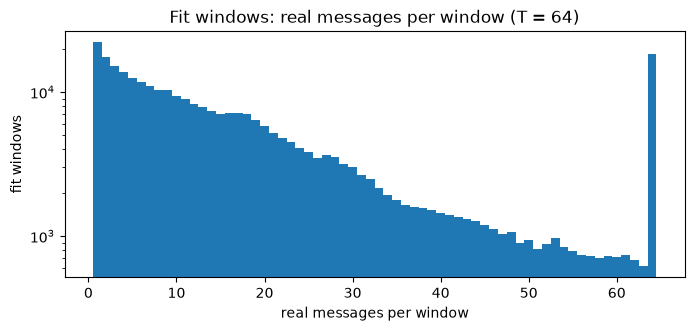

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(fit.n_messages, bins=np.arange(1, 66) - 0.5, color="tab:blue")
ax.set_xlabel("real messages per window"); ax.set_ylabel("fit windows"); ax.set_yscale("log")
ax.set_title("Fit windows: real messages per window (T = 64)")
plt.show()

## 2. Model

`task.encoder.model.ConvAutoencoder`, unchanged: layers with their output shapes for one batch of 2 windows and the
trainable parameter count.

In [5]:
model = ConvAutoencoder(settings.architecture())
x0, m0 = torch.zeros(2, 64, 13), torch.ones(2, 64, dtype=torch.bool)
table = []
hooks = [mod.register_forward_hook(lambda mod, inp, out, name=name: table.append(
    (name, type(mod).__name__, tuple(out.shape[1:]), sum(p.numel() for p in mod.parameters()))))
    for name, mod in model.named_modules() if isinstance(mod, (torch.nn.Conv1d, torch.nn.ConvTranspose1d, torch.nn.Linear))]
model.eval()
with torch.no_grad():
    recon0, z0 = model(x0, m0)
for h in hooks:
    h.remove()
display(pd.DataFrame(table, columns=["layer", "type", "output (per window)", "params"]))
print("reconstruction:", tuple(recon0.shape[1:]), " z:", tuple(z0.shape[1:]))
print(f"trainable parameters: {count_params(model):,} (run: {summary['params']:,})")

,layer,type,output (per window),params
0,encoder.conv.0,Conv1d,"(32, 64)",1376
1,encoder.conv.3,Conv1d,"(64, 32)",6208
2,encoder.conv.6,Conv1d,"(64, 16)",12352
3,encoder.fc,Linear,"(16,)",16400
4,decoder.fc,Linear,"(1024,)",17408
5,decoder.deconv.1,ConvTranspose1d,"(64, 32)",16448
6,decoder.deconv.4,ConvTranspose1d,"(32, 64)",8224
7,decoder.deconv.7,Conv1d,"(13, 64)",1261


reconstruction: (64, 13)  z: (16,)
trainable parameters: 80,189 (run: 80,189)


## 3. Training record

What `task.autoencoder_t64.train` wrote: the summary (with the validation thresholds), the per-epoch history (train vs
validation masked MSE, best epoch, LR drops) and log lines.

{
  "run_id": "seed0",
  "params": 80189,
  "best_epoch": 161,
  "best_val_loss": 0.14517976122667867,
  "epochs_run": 171,
  "stop_reason": "early_stopping",
  "train_seconds": 7460.2,
  "train_windows": 338001,
  "fit_windows": 304733,
  "val_windows": 33268,
  "fit_vehicles": 4660,
  "val_vehicles": 518,
  "mahalanobis_fitted_on": "z of the fit windows (train minus the validation vehicles), both classes",
  "splits_opened": [
    "train"
  ],
  "label_reads": [],
  "wall_seconds": 7465.3,
  "device": "mps"
}
LR halvings: 7 | thresholds: {"reconstruction": {"p95": 0.3917994499206543, "p99": 0.6005575656890869}, "mahalanobis": {"p95": 6.402968883514404, "p99": 9.210713386535645}}


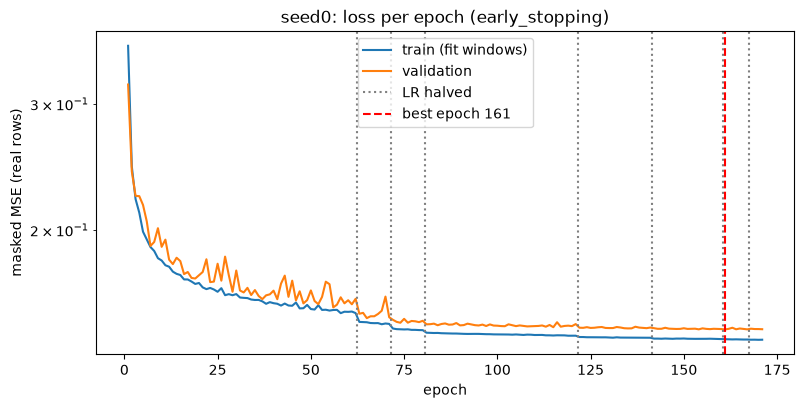

2026-11-10T18:24:51 train windows 338,001 (2s to open), shape (64, 13) + mask; fit 304,733 / val 33,268 windows; vehicles 4,660 / 518; val = 0.1 of the train vehicles (split seed 0)
2026-11-10T18:24:51 padding share fit 0.711 / val 0.709, real messages per window median 13
2026-11-10T18:24:51 ConvAutoencoder (task/encoder): 80,189 trainable parameters, input 14 x 64, z 16
2026-11-10T18:24:52 fit: 304,733 windows, val: 33,268 windows, batch 256, device mps
2026-11-10T18:25:02 epoch   1  train 0.36164  val 0.31928  lr 1.00e-03  9.4s *best
2026-11-10T18:25:08 epoch   2  train 0.24513  val 0.24129  lr 1.00e-03  6.4s *best
...
2026-11-10T20:17:34 lr reduced 1.00e-03 -> 5.00e-04 (validation loss flat for 6 epochs)
2026-11-10T20:18:32 lr reduced 5.00e-04 -> 2.50e-04 (validation loss flat for 6 epochs)
...
2026-11-10T20:29:12 epoch 171  train 0.14046  val 0.14529  lr 7.81e-06  6.4s (no improvement 10/10)
2026-11-10T20:29:12 early stopping: no improvement for 10 epochs; best epoch 161 val 0.145

In [6]:
print(json.dumps({k: v for k, v in summary.items() if k not in ("thresholds", "lr_changes")}, indent=2))
print("LR halvings:", len(summary["lr_changes"]), "| thresholds:", json.dumps(summary["thresholds"]["window"]))
history = pd.read_json(RUN / "history.jsonl", lines=True)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(history.epoch, history.train_loss, label="train (fit windows)")
ax.plot(history.epoch, history.val_loss, label="validation")
for k, c in enumerate(summary["lr_changes"]):
    ax.axvline(c["after_epoch"] + 0.5, color="grey", ls=":", label="LR halved" if k == 0 else None)
ax.axvline(summary["best_epoch"], color="red", ls="--", label=f"best epoch {summary['best_epoch']}")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("masked MSE (real rows)"); ax.legend()
ax.set_title(f"{RUN.name}: loss per epoch ({summary['stop_reason']})")
plt.show()
log = (RUN / "train.log").read_text().splitlines()
print("\n".join(log[:6] + ["..."] + [l for l in log if "lr reduced" in l][:2] + ["..."] + log[-3:-1]))

## 4. Reconstruction on val

Load `best.pt`, rebuild the validation windows and compare with the score files the run wrote (same windows, same
order). A few long validation windows: input vs reconstruction for three features. Then the mean error per feature.

val ids aligned with the score files: True
max |recomputed - stored| on val: reconstruction 0.00e+00, Mahalanobis 1.68e-06
val windows 33,268; mean window error 0.1297 (run's best val loss, pooled over rows: 0.1452)
reconstruction: val thresholds recomputed {'p95': 0.3917994499206543, 'p99': 0.6005575656890869} = summary: True
mahalanobis: val thresholds recomputed {'p95': 6.402968883514404, 'p99': 9.210713386535645} = summary: True


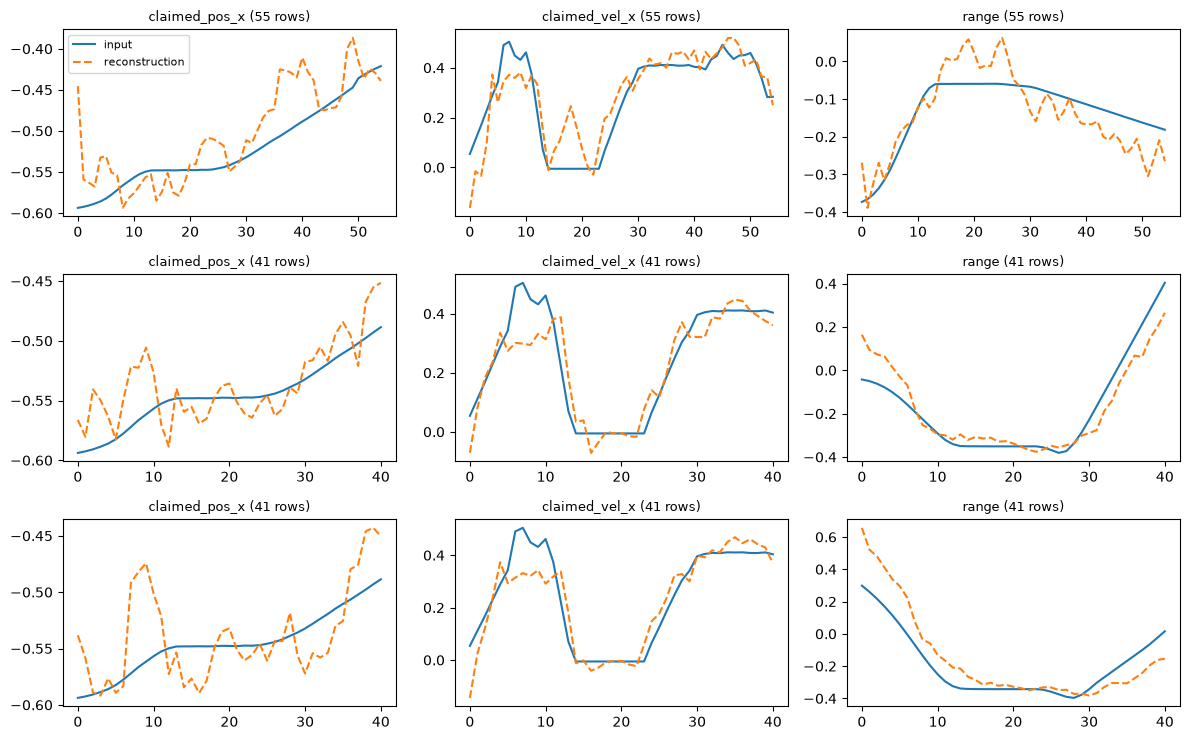

,val MSE
claimed_acl_x,0.3905
claimed_acl_y,0.3766
log_dtau,0.2551
bearing,0.1525
rx_vel_x,0.1229
rx_vel_y,0.1078
claimed_vel_x,0.0778
claimed_vel_y,0.0678
range,0.0401
claimed_pos_y,0.0282


In [7]:
trainer = Trainer.from_checkpoint(RUN / "best.pt")
val_files = ScoreFiles(RUN, "val").load()
val_out = trainer.score(val.x, val.mask, keep_recon=True)
state = np.load(RUN / "mahalanobis.npz")
maha = Mahalanobis(settings.maha_ridge); maha.mean, maha.precision = state["mean"], state["precision"]
print("val ids aligned with the score files:", np.array_equal(val_files["ids"], np.asarray(val.ids).astype(str)))
print(f"max |recomputed - stored| on val: reconstruction {np.abs(val_out['error'] - val_files['recon_error']).max():.2e}, "
      f"Mahalanobis {np.abs(maha.score(val_out['z']) - val_files['mahalanobis']).max():.2e}")
print(f"val windows {len(val):,}; mean window error {val_out['error'].mean():.4f} "
      f"(run's best val loss, pooled over rows: {summary['best_val_loss']:.4f})")
for name, key in (("reconstruction", "recon_error"), ("mahalanobis", "mahalanobis")):
    q = {f"p{round(p * 100)}": float(np.quantile(val_files[key], p)) for p in settings.threshold_quantiles}
    print(f"{name}: val thresholds recomputed {q} = summary: "
          f"{all(np.isclose(q[k], summary['thresholds']['window'][name][k]) for k in q)}")

show = ["claimed_pos_x", "claimed_vel_x", "range"]
picks = np.flatnonzero(val.n_messages >= 40)[:3]
fig, axes = plt.subplots(len(picks), len(show), figsize=(12, 2.5 * len(picks)), squeeze=False)
for r, i in enumerate(picks):
    n = val.n_messages[i]
    for c, f in enumerate(show):
        j = FEATURES.index(f)
        axes[r, c].plot(val.x[i, :n, j], label="input")
        axes[r, c].plot(val_out["recon"][i, :n, j], "--", label="reconstruction")
        axes[r, c].set_title(f"{f} ({n} rows)", fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); plt.show()
pd.Series(val_out["error_feature"].mean(0), index=FEATURES, name="val MSE").sort_values(ascending=False).round(4).to_frame()

## 5. Test

**Scoring first, labels after.** `task.autoencoder_t64.evaluate` scored every test window from x + mask and wrote
`test_*.npy`; the cell below re-scores the test windows from `best.pt` and compares. Thresholds are the 95th / 99th
percentile of the **validation** scores (mixed classes, unlabelled). An alarm is `score >= threshold`.

In [8]:
test = store.open("test")
test_files = ScoreFiles(RUN, "test").load()
test_out = trainer.score(test.x, test.mask)
print("test ids aligned with the score files:", np.array_equal(test_files["ids"], np.asarray(test.ids).astype(str)))
print(f"max |recomputed - stored| on test: reconstruction {np.abs(test_out['error'] - test_files['recon_error']).max():.2e}, "
      f"Mahalanobis {np.abs(maha.score(test_out['z']) - test_files['mahalanobis']).max():.2e}")
print("test label reads before this point:", test.label_reads)
scores = {"reconstruction": test_files["recon_error"].astype(float), "mahalanobis": test_files["mahalanobis"].astype(float)}
n_msg = test_files["n_messages"].astype(int)

test ids aligned with the score files: True
max |recomputed - stored| on test: reconstruction 0.00e+00, Mahalanobis 8.28e-07
test label reads before this point: []


Labels are read now (GridSybil = positive). Every headline number of `results.json` is recomputed here with sklearn and compared.

In [9]:
y = np.asarray(test.labels("notebook: test labels after scoring")).astype(int)
print(f"test windows {len(y):,}: benign {int((y == 0).sum()):,}, GridSybil {int(y.sum()):,} (share {y.mean():.3f} = PR-AUC chance level)")
rows, ok = [], True
for name, s in scores.items():
    stored = results["window"][name]
    auc, ap = roc_auc_score(y, s), average_precision_score(y, s)
    ok &= bool(np.isclose(auc, stored["auroc"]) and np.isclose(ap, stored["pr_auc"]))
    for q, m in stored["thresholds"].items():
        pred = s >= m["threshold"]
        recall, fpr = pred[y == 1].mean(), pred[y == 0].mean()
        ok &= bool(np.isclose(recall, m["recall"]) and np.isclose(fpr, m["benign_fpr"]))
        rows.append({"score": name, "AUROC": auc, "PR-AUC": ap, "threshold": q, "θ": m["threshold"], "precision": m["precision"],
                     "recall": recall, "F1": m["f1"], "benign FPR": fpr, **m["confusion"]})
length_auc = roc_auc_score(y, -n_msg.astype(float))
ok &= bool(np.isclose(length_auc, results["length_only"]["auroc"]))
print("recomputed metrics equal results.json:", ok)
res = pd.DataFrame(rows).set_index(["score", "threshold"])
display(res.round(4))
print(f"length alone, fixed rule score = -n_messages: AUROC {length_auc:.4f}, PR-AUC {results['length_only']['pr_auc']:.4f}")
print(f"share of validation windows above the thresholds (by construction 5% / 1%): {json.dumps(results['val_alarm_rate'])}")

test windows 38,426: benign 12,741, GridSybil 25,685 (share 0.668 = PR-AUC chance level)
recomputed metrics equal results.json: True


AUROC  PR-AUC       θ  precision  recall      F1  \
score          threshold                                                      
reconstruction val_p95    0.4819  0.6602  0.3918     0.6509  0.0450  0.0842   
               val_p99    0.4819  0.6602  0.6006     0.7289  0.0097  0.0192   
mahalanobis    val_p95    0.3515  0.5993  6.4030     0.6230  0.0470  0.0875   
               val_p99    0.3515  0.5993  9.2107     0.7547  0.0062  0.0124   

                          benign FPR     tn   fp     fn    tp  
score          threshold                                       
reconstruction val_p95        0.0487  12121  620  24529  1156  
               val_p99        0.0073  12648   93  25435   250  
mahalanobis    val_p95        0.0574  12010  731  24477  1208  
               val_p99        0.0041  12689   52  25525   160

length alone, fixed rule score = -n_messages: AUROC 0.5348, PR-AUC 0.6985
share of validation windows above the thresholds (by construction 5% / 1%): {"reconstruction": {"p95": 0.0500180353492846, "p99": 0.010009618852951785}, "mahalanobis": {"p95": 0.0500180353492846, "p99": 0.010009618852951785}}


AUROC by window length: 1–3 rows vs ≥ 4 rows, then the four bins `task/encoder` uses. The length column is the fixed
rule −n_messages inside the bin (`task/encoder` reports the better of the two directions per bin instead).

In [10]:
def strata_table(key):
    t = pd.DataFrame(results[key]).T
    t.columns = ["windows", "benign", "GridSybil", "AUROC reconstruction", "AUROC Mahalanobis", "AUROC length (−n)"]
    return t.astype({"windows": int, "benign": int, "GridSybil": int}).round(4)

for name, lo, hi in SHORT_LONG_STRATA:
    sel = (n_msg >= lo) & (n_msg <= hi)
    assert np.isclose(roc_auc_score(y[sel], scores["reconstruction"][sel]), results["strata_short_long"][name]["auroc_reconstruction"])
display(strata_table("strata_short_long")); display(strata_table("strata_encoder_bins"))

,windows,benign,GridSybil,AUROC reconstruction,AUROC Mahalanobis,AUROC length (−n)
1-3 rows,6720,1822,4898,0.3610,0.3169,0.5051
>=4 rows,31706,10919,20787,0.5117,0.3621,0.5157


,windows,benign,GridSybil,AUROC reconstruction,AUROC Mahalanobis,AUROC length (−n)
n<=3,6720,1822,4898,0.3610,0.3169,0.5051
4-16,15865,5236,10629,0.4726,0.2916,0.5361
17-48,11800,4452,7348,0.5582,0.3314,0.4927
49-64,4041,1231,2810,0.5145,0.4170,0.4733


Per track (one link = one receiver hearing one sender pseudonym; the id is the window id without its window index and
holds the true sender, F13): max and mean of the window scores of the track, thresholds = p95 / p99 of the validation
track scores.

In [11]:
tracks = TrackScores(track_ids(test_files["ids"]))
y_trk, mixed = tracks.track_labels(y)
t = results["track"]
print(f"test tracks {len(tracks):,} (benign {int((y_trk == 0).sum()):,}, GridSybil {int(y_trk.sum()):,}); mixed-label tracks {mixed}; "
      f"share with a single window {t['share_single_window']:.3f}")
rows = []
for name, s in scores.items():
    for how, agg in tracks.aggregate(s).items():
        m = t[f"{name}_{how}"]
        assert np.isclose(roc_auc_score(y_trk, agg), m["auroc"])
        rows.append({"score": name, "track": how, "AUROC": m["auroc"], "PR-AUC": m["pr_auc"],
                     **{f"{k} @ {q}": m["thresholds"][q][k] for q in ("val_p95", "val_p99") for k in ("recall", "benign_fpr")}})
pd.DataFrame(rows).set_index(["score", "track"]).round(4)

test tracks 35,957 (benign 12,053, GridSybil 23,904); mixed-label tracks 0; share with a single window 0.945


AUROC  PR-AUC  recall @ val_p95  benign_fpr @ val_p95  \
score          track                                                           
reconstruction max    0.4806  0.6561            0.0453                0.0492   
               mean   0.4795  0.6541            0.0440                0.0497   
mahalanobis    max    0.3399  0.5856            0.0471                0.0674   
               mean   0.3347  0.5796            0.0427                0.0661   

                      recall @ val_p99  benign_fpr @ val_p99  
score          track                                          
reconstruction max              0.0095                0.0071  
               mean             0.0089                0.0081  
mahalanobis    max              0.0081                0.0086  
               mean             0.0085                0.0103

Score histograms on the test windows, benign vs GridSybil, with the validation thresholds.

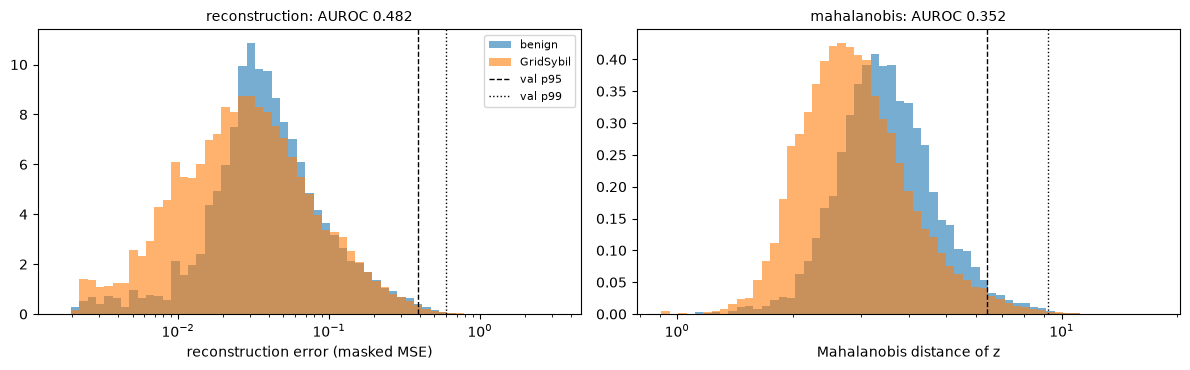

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (name, s) in zip(axes, scores.items()):
    bins = np.logspace(np.log10(max(s.min(), 1e-5)), np.log10(s.max()), 60)
    ax.hist(s[y == 0], bins=bins, alpha=0.6, density=True, label="benign")
    ax.hist(s[y == 1], bins=bins, alpha=0.6, density=True, label="GridSybil")
    for q, ls in (("p95", "--"), ("p99", ":")):
        ax.axvline(summary["thresholds"]["window"][name][q], color="black", ls=ls, lw=1, label=f"val {q}")
    ax.set_xscale("log"); ax.set_title(f"{name}: AUROC {roc_auc_score(y, s):.3f}", fontsize=10)
    ax.set_xlabel("reconstruction error (masked MSE)" if name == "reconstruction" else "Mahalanobis distance of z")
axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

Mean per-feature reconstruction error by class on the test windows, and the per-feature AUROC.

In [13]:
pd.DataFrame(results["per_feature"]).T.rename(columns={"benign_mean": "benign", "gridsybil_mean": "GridSybil", "auroc": "AUROC"}).round(4).sort_values("AUROC", ascending=False)

,benign,GridSybil,AUROC
range,0.0188,0.0490,0.6521
claimed_pos_y,0.0126,0.0324,0.6240
log_dtau,0.1517,0.3016,0.6093
claimed_pos_x,0.0154,0.0316,0.5669
bearing,0.1156,0.1638,0.5502
rx_pos_y,0.0171,0.0210,0.5083
rx_pos_x,0.0171,0.0195,0.4970
rx_vel_y,0.1058,0.0990,0.4792
rx_vel_x,0.1264,0.1157,0.4684
claimed_acl_y,0.4058,0.3925,0.4610


## 6. Context (not a controlled comparison)

Next to this run: the existing T = 64 **benign-only** autoencoder of `task/encoder` (same architecture, same test
windows; numbers read from `task/encoder/runs/evaluation/results.json`). Differences besides the training set: its
validation set and thresholds are benign-only (362 benign vehicles), its early-stopping patience is 5 and plateau
patience 3 (here 10 and 5), and it has 3 seeds (here 1). The T = 48 unlabelled run of `task/autoencoder` (README:
AUROC 0.484) uses differently cut windows.

In [14]:
ctx = results["context_task_encoder_benign_only_T64"]
def row(label, auc, ap, p95, p99, fpr_key):
    return {"model": label, "AUROC": auc, "PR-AUC": ap, "recall @ val p95": p95["recall"], "benign FPR @ val p95": p95[fpr_key],
            "recall @ val p99": p99["recall"], "benign FPR @ val p99": p99[fpr_key]}
rows = []
for name in ("reconstruction", "mahalanobis"):
    w = results["window"][name]
    rows.append(row(f"this run (unlabelled, benign + GridSybil), {name}", w["auroc"], w["pr_auc"], w["thresholds"]["val_p95"], w["thresholds"]["val_p99"], "benign_fpr"))
for key, name in (("ae:recon_error", "reconstruction"), ("ae:mahalanobis", "mahalanobis")):
    s0 = ctx[key]["seed0"]
    rows.append(row(f"task/encoder benign-only AE seed 0, {name}", s0["auroc"], s0["pr_auc"], s0["thresholds"]["val_p95"], s0["thresholds"]["val_p99"], "fpr"))
display(pd.DataFrame(rows).set_index("model").round(4))
print("task/encoder benign-only AE, mean ± std over its 3 seeds: reconstruction AUROC "
      f"{ctx['ae:recon_error']['mean_over_seeds']['auroc']['mean']:.4f} ± {ctx['ae:recon_error']['mean_over_seeds']['auroc']['std']:.4f}, "
      f"Mahalanobis {ctx['ae:mahalanobis']['mean_over_seeds']['auroc']['mean']:.4f} ± {ctx['ae:mahalanobis']['mean_over_seeds']['auroc']['std']:.4f}")
print("task/encoder length-only record:", json.dumps(ctx["length_only"]))
print(f"this run, GridSybil share of the fit windows: {results['training_set']['fit']['gridsybil_share']:.4f} "
      f"(train {results['training_set']['train']['gridsybil_share']:.4f}, val {results['training_set']['val']['gridsybil_share']:.4f})")

,AUROC,PR-AUC,recall @ val p95,benign FPR @ val p95,recall @ val p99,benign FPR @ val p99
model,,,,,,
"this run (unlabelled, benign + GridSybil), reconstruction",0.4819,0.6602,0.0450,0.0487,0.0097,0.0073
"this run (unlabelled, benign + GridSybil), mahalanobis",0.3515,0.5993,0.0470,0.0574,0.0062,0.0041
"task/encoder benign-only AE seed 0, reconstruction",0.6546,0.8010,0.1937,0.0496,0.1026,0.0117
"task/encoder benign-only AE seed 0, mahalanobis",0.3334,0.5975,0.0474,0.0505,0.0167,0.0115


task/encoder benign-only AE, mean ± std over its 3 seeds: reconstruction AUROC 0.6554 ± 0.0024, Mahalanobis 0.3188 ± 0.0156
task/encoder length-only record: {"auroc_plus_n": 0.46515250292064153, "auroc_minus_n": 0.5348474970793584, "direction": "-n_messages (shorter = GridSybil)"}
this run, GridSybil share of the fit windows: 0.6462 (train 0.6448, val 0.6314)


## 7. Analysis

Numbers from the outputs above (run `seed0`, one seed, no confidence intervals; a side experiment, not a thesis result).

- **Training worked as a reconstruction model.** Validation masked MSE fell from 0.319 (epoch 1) to **0.1452** (best,
  epoch 161); early stopping (patience 10) ended the run at epoch 171 after 7 LR halvings (1e-3 to 7.8e-6). Fit and
  validation end close (0.141 vs 0.145). An epoch took 6.4 s on MPS (median, about 18 min of computing); the recorded
  wall-clock is 124 min because eight epochs (40–47) stalled for 4–33 min each while the machine was busy or asleep.
- **Reconstruction error does not detect GridSybil.** Window AUROC **0.482**, PR-AUC 0.660 (chance 0.668). At the
  validation p95 threshold: benign FPR 0.049, recall **0.045**, precision 0.651, F1 0.084; at p99: recall 0.010, FPR
  0.007. The alarm rate is the same in both classes, so the threshold flags about 5% of everything.
- **Mahalanobis on z is below chance.** Window AUROC **0.352** (PR-AUC 0.599): GridSybil windows lie closer to the
  centre of the fit z than benign ones. 64.6% of the fit windows are GridSybil and the Gaussian is fitted on all of
  them, so the "typical" window is a GridSybil window. Recall 0.047 at benign FPR 0.057 (p95).
- **Tracks change nothing.** 35,957 test tracks, none with mixed labels, 94.5% with a single window: reconstruction
  max / mean AUROC 0.481 / 0.480, Mahalanobis 0.340 / 0.335.
- **By length.** 1–3 rows: reconstruction 0.361, Mahalanobis 0.317 (6,720 windows; short GridSybil windows are
  rebuilt better than short benign ones). ≥ 4 rows: 0.512 and 0.362 (31,706 windows). In `task/encoder`'s bins the
  reconstruction AUROC is 0.361 / 0.473 / 0.558 / 0.515 for ≤ 3 / 4–16 / 17–48 / 49–64 rows: at best slightly above
  chance.
- **Length alone** (fixed rule −n_messages, shorter = more anomalous): AUROC **0.535**, PR-AUC 0.699; 0.505 on 1–3
  rows and 0.516 on ≥ 4 rows. It is higher than both model scores. `task/encoder` reports the same 0.535 for the same
  direction, but it chose the direction on the test labels (the other direction gives 0.465), and inside its length
  bins it reports the better direction per bin.
- **Per feature.** The error on range (0.652), claimed_pos_y (0.624) and log_dtau (0.609) is higher for GridSybil;
  the error on claimed velocity is lower for GridSybil (0.270 / 0.271), which cancels the signal in the mean over
  features.
- **Context.** The benign-only autoencoder of `task/encoder` (same architecture and test windows) reaches
  reconstruction AUROC 0.655 (seed 0; 0.655 ± 0.002 over 3 seeds) and recall 0.194 at benign FPR 0.050; its
  Mahalanobis score is also below chance (0.333). Its validation set, thresholds and patience differ, so this is
  context, not a controlled comparison. The T = 48 unlabelled run (`task/autoencoder`, 0.484) gives the same picture
  as this run: when GridSybil is two thirds of the unlabelled training data, the autoencoder learns it as normal.
- **Limits.** One seed; no confidence interval; GridSybil only; window counts within a vehicle are not independent;
  track ids contain the true sender (F13).